# DS-550 Machine Learning - Assignment 1
**Student Name:** Muhammad Imran Mian  
**Roll No:** MSDSF25A007  
**Program:** MS Data Science (Batch F26)  
**University:** PUCIT New Campus Lahore  
**Instructor:** Dr. Syed Muhammad Ali  
**Deadline:** September 30, 2026, 11:59 PM  


---
# Question 1: Theoretical Derivations from Maximum Likelihood Estimation (MLE)

## Part (i): Linear Regression

### 1. Probabilistic Model Setup
Assume each observed response $y^{(i)}$ differs from the linear predictor by an additive Gaussian noise term:
$$y^{(i)} = \theta^T x^{(i)} + \epsilon^{(i)}$$
where $\epsilon^{(i)} \stackrel{\text{I.I.D.}}{\sim} \mathcal{N}(0, \sigma^2)$. The probability density of $y^{(i)}$ given $x^{(i)}$ parameterized by $\theta$ is:
$$P(y^{(i)} \mid x^{(i)}; \theta) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(y^{(i)} - \theta^T x^{(i)})^2}{2\sigma^2} \right)$$

### 2. Likelihood and Log-Likelihood Function
For $m$ independent observations, the likelihood function is:
$$\mathcal{L}(\theta) = \prod_{i=1}^m \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(y^{(i)} - \theta^T x^{(i)})^2}{2\sigma^2} \right)$$
Taking the natural logarithm:
$$\ell(\theta) = \ln \mathcal{L}(\theta) = m \ln\left(\frac{1}{\sqrt{2\pi\sigma^2}}\right) - \frac{1}{2\sigma^2} \sum_{i=1}^m (y^{(i)} - \theta^T x^{(i)})^2$$

### 3. Connection to Least Squares Cost
Maximizing $\ell(\theta)$ with respect to $\theta$ is mathematically equivalent to minimizing the Sum of Squared Residuals:
$$J(\theta) = \frac{1}{2m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)})^2 \quad \text{where } h_\theta(x) = \theta^T x$$

### 4. Gradient and Update Rule
Differentiating $J(\theta)$ with respect to $\theta_j$:
$$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)}$$
The **Batch Gradient Descent update rule** with learning rate $\alpha > 0$ is:
$$\theta_j := \theta_j - \alpha \frac{\partial J(\theta)}{\partial \theta_j} = \theta_j - \frac{\alpha}{m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)}$$
In vectorized form:
$$\theta := \theta - \frac{\alpha}{m} X^T (X\theta - y)$$

---

## Part (ii): Logistic Regression

### 1. Probabilistic Model Setup
In binary classification with $y^{(i)} \in \{0, 1\}$, we model the class posterior using the logistic sigmoid function:
$$h_\theta(x) = \sigma(\theta^T x) = \frac{1}{1 + e^{-\theta^T x}}$$
$$P(y^{(i)} \mid x^{(i)}; \theta) = (h_\theta(x^{(i)}))^{y^{(i)}} (1 - h_\theta(x^{(i)}))^{1 - y^{(i)}}$$

### 2. Log-Likelihood Function
$$\ell(\theta) = \ln \mathcal{L}(\theta) = \sum_{i=1}^m \left[ y^{(i)} \ln(h_\theta(x^{(i)})) + (1 - y^{(i)}) \ln(1 - h_\theta(x^{(i)})) \right]$$

### 3. Gradient Derivation
Using the sigmoid derivative identity $\frac{\partial h_\theta(x^{(i)})}{\partial \theta_j} = h_\theta(x^{(i)})(1 - h_\theta(x^{(i)})) x_j^{(i)}$:
$$\frac{\partial \ell(\theta)}{\partial \theta_j} = \sum_{i=1}^m (y^{(i)} - h_\theta(x^{(i)})) x_j^{(i)}$$

### 4. Update Rules
* **Gradient Ascent (Maximizing Likelihood):**
  $$\theta_j := \theta_j + \alpha \sum_{i=1}^m (y^{(i)} - h_\theta(x^{(i)})) x_j^{(i)}$$
* **Gradient Descent (Minimizing Cross-Entropy Cost $J(\theta) = -\frac{1}{m}\ell(\theta)$):**
  $$\theta_j := \theta_j - \frac{\alpha}{m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)}$$


---
# Question 2 [P]: Linear Regression for Housing Price Prediction
We implement both the closed-form **Normal Equation** and iterative **Batch Gradient Descent** with feature standardization, evaluating on the official test set.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load datasets
train_df = pd.read_csv('Data/Q2/Question 2 Dataset-train.csv')
test_df = pd.read_csv('Data/Q2/Question 2 Dataset-test.csv')

features = ['bedrooms', 'living_in_m2', 'real_bathrooms']
target = 'price'

X_train_raw = train_df[features].values
y_train = train_df[target].values
X_test_raw = test_df[features].values
y_test = test_df[target].values

print(f"Train samples: {len(X_train_raw)}, Test samples: {len(X_test_raw)}")


Train samples: 13603, Test samples: 6700


In [2]:
# Method A: Normal Equations (Closed-Form Analytical Solution)
X_train_ne = np.column_stack([np.ones(len(X_train_raw)), X_train_raw])
X_test_ne = np.column_stack([np.ones(len(X_test_raw)), X_test_raw])

theta_ne = np.linalg.pinv(X_train_ne.T @ X_train_ne) @ (X_train_ne.T @ y_train)

y_pred_ne = X_test_ne @ theta_ne
rmse_ne = np.sqrt(mean_squared_error(y_test, y_pred_ne))
mae_ne = mean_absolute_error(y_test, y_pred_ne)
r2_ne = r2_score(y_test, y_pred_ne)

print("--- Normal Equation Results ---")
print(f"Intercept (theta_0) : {theta_ne[0]:,.4f}")
print(f"Bedrooms (theta_1)  : {theta_ne[1]:,.4f}")
print(f"Living Area (theta_2): {theta_ne[2]:,.4f}")
print(f"Bathrooms (theta_3) : {theta_ne[3]:,.4f}")
print(f"Test RMSE: ${rmse_ne:,.2f}")
print(f"Test MAE : ${mae_ne:,.2f}")
print(f"Test R^2 : {r2_ne:.4f}")


--- Normal Equation Results ---
Intercept (theta_0) : 168,296.7234
Bedrooms (theta_1)  : -35,199.4204
Living Area (theta_2): 2,022.3698
Bathrooms (theta_3) : 10,857.6445
Test RMSE: $163,372.48
Test MAE : $130,582.33
Test R^2 : 0.3833


In [3]:
# Method B: Batch Gradient Descent with Feature Scaling
mu = np.mean(X_train_raw, axis=0)
sigma = np.std(X_train_raw, axis=0)

X_train_scaled = (X_train_raw - mu) / sigma
X_test_scaled = (X_test_raw - mu) / sigma

X_train_gd = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled])
X_test_gd = np.column_stack([np.ones(len(X_test_scaled)), X_test_scaled])

m = len(y_train)
theta_gd = np.zeros(X_train_gd.shape[1])
alpha = 0.05
epochs = 500
cost_history = []

for epoch in range(epochs):
    preds = X_train_gd @ theta_gd
    errors = preds - y_train
    cost = (1.0 / (2.0 * m)) * np.sum(errors ** 2)
    cost_history.append(cost)
    gradient = (1.0 / m) * (X_train_gd.T @ errors)
    theta_gd -= alpha * gradient

y_pred_gd = X_test_gd @ theta_gd
rmse_gd = np.sqrt(mean_squared_error(y_test, y_pred_gd))
mae_gd = mean_absolute_error(y_test, y_pred_gd)
r2_gd = r2_score(y_test, y_pred_gd)

print("--- Gradient Descent Results ---")
print(f"Test RMSE: ${rmse_gd:,.2f}")
print(f"Test MAE : ${mae_gd:,.2f}")
print(f"Test R^2 : {r2_gd:.4f}")
print(f"Max Absolute Prediction Difference between NE and GD: {np.max(np.abs(y_pred_ne - y_pred_gd)):.4f}")


--- Gradient Descent Results ---
Test RMSE: $163,372.72
Test MAE : $130,583.11
Test R^2 : 0.3833
Max Absolute Prediction Difference between NE and GD: 77.6675


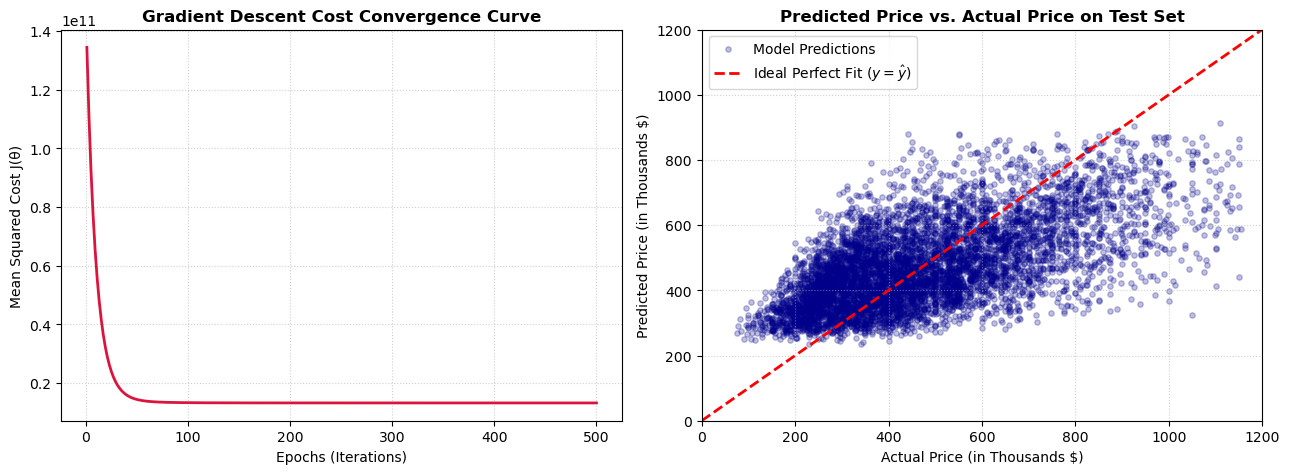

In [4]:
# Visualizing Cost Convergence & Predictions vs Actual
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), cost_history, color='crimson', lw=2)
plt.title('Gradient Descent Cost Convergence Curve', fontsize=12, fontweight='bold')
plt.xlabel('Epochs (Iterations)')
plt.ylabel('Mean Squared Cost J(θ)')
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 2, 2)
plt.scatter(y_test / 1000, y_pred_ne / 1000, color='darkblue', alpha=0.25, s=15, label='Model Predictions')
plt.plot([0, 1200], [0, 1200], 'r--', lw=2, label='Ideal Perfect Fit ($y = \hat{y}$)')
plt.title('Predicted Price vs. Actual Price on Test Set', fontsize=12, fontweight='bold')
plt.xlabel('Actual Price (in Thousands $)')
plt.ylabel('Predicted Price (in Thousands $)')
plt.xlim(0, 1200)
plt.ylim(0, 1200)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


---
# Question 3 [P]: Wind Tunnel Projectile Experiment
We compare an exact **5th-Degree Interpolating Polynomial** with a parsimonious **Quadratic Least Squares Fit** to estimate projectile drag force at $v = 750\text{ ft/sec}$ ($x = 7.5$).


In [5]:
# Given Wind Tunnel Dataset
# Velocity x: units of 100 ft/sec; Force y: units of 100 lb
x = np.array([0, 2, 4, 6, 8, 10], dtype=float)
y = np.array([0, 2.90, 14.8, 39.6, 74.3, 119.0], dtype=float)

# (i) 5th-Degree Interpolating Polynomial (Vandermonde Matrix System)
V = np.vander(x, N=len(x), increasing=True)
c_interp = np.linalg.solve(V, y)

# (ii) Quadratic Polynomial via Least Squares Regression
X_quad = np.column_stack([np.ones_like(x), x, x**2])
c_quad = np.linalg.inv(X_quad.T @ X_quad) @ (X_quad.T @ y)

print("Interpolation Coefficients [c0...c5]:", np.round(c_interp, 6))
print("Quadratic Regression Coefficients [c0, c1, c2]:", np.round(c_quad, 6))

# Evaluation at target velocity = 750 ft/sec (x = 7.5)
x_target = 7.5
pred_interp_hundred = np.polyval(c_interp[::-1], x_target)
pred_quad_hundred = c_quad[0] + c_quad[1] * x_target + c_quad[2] * (x_target ** 2)

print(f"\n--- Estimations at Velocity = 750 ft/sec (x = 7.5) ---")
print(f"5th-Degree Interpolation Prediction: {pred_interp_hundred:.4f} hundred lb = {pred_interp_hundred * 100:,.2f} lb")
print(f"Quadratic Regression Prediction    : {pred_quad_hundred:.4f} hundred lb = {pred_quad_hundred * 100:,.2f} lb")
print(f"Absolute Difference                : {abs(pred_interp_hundred - pred_quad_hundred)*100:.2f} lb")


Interpolation Coefficients [c0...c5]: [ 0.        1.7125   -1.194792  0.661458 -0.070052  0.002604]
Quadratic Regression Coefficients [c0, c1, c2]: [ 0.064286 -1.4875    1.340179]

--- Estimations at Velocity = 750 ft/sec (x = 7.5) ---
5th-Degree Interpolation Prediction: 64.8384 hundred lb = 6,483.84 lb
Quadratic Regression Prediction    : 64.2931 hundred lb = 6,429.31 lb
Absolute Difference                : 54.53 lb


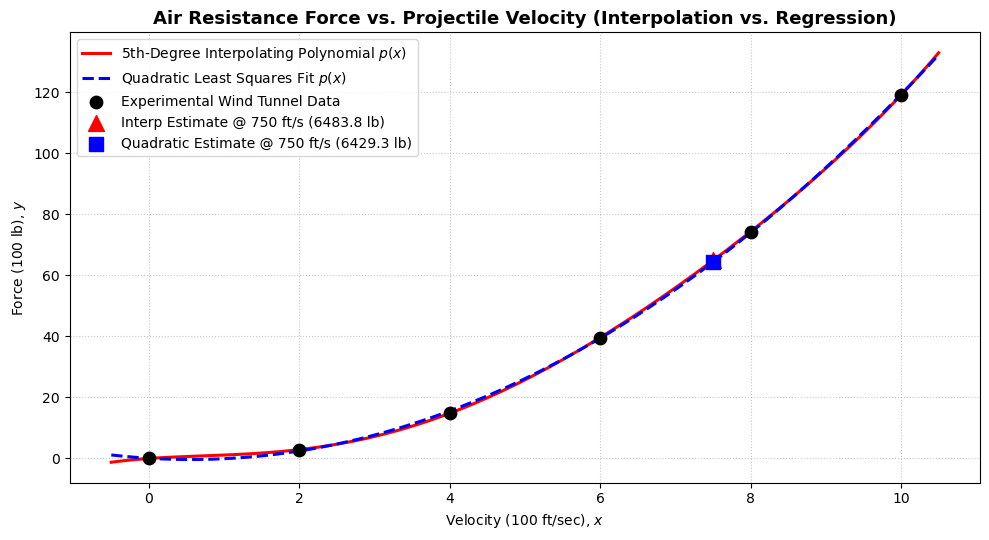

In [6]:
# Plotting Interpolation vs Regression
x_dense = np.linspace(-0.5, 10.5, 400)
y_interp_dense = np.polyval(c_interp[::-1], x_dense)
y_quad_dense = c_quad[0] + c_quad[1] * x_dense + c_quad[2] * (x_dense ** 2)

plt.figure(figsize=(10, 5.5))
plt.plot(x_dense, y_interp_dense, 'r-', lw=2.2, label='5th-Degree Interpolating Polynomial $p(x)$')
plt.plot(x_dense, y_quad_dense, 'b--', lw=2.2, label='Quadratic Least Squares Fit $p(x)$')
plt.scatter(x, y, color='black', s=80, zorder=5, label='Experimental Wind Tunnel Data')
plt.scatter([x_target], [pred_interp_hundred], color='red', marker='^', s=130, zorder=6,
            label=f'Interp Estimate @ 750 ft/s ({pred_interp_hundred*100:.1f} lb)')
plt.scatter([x_target], [pred_quad_hundred], color='blue', marker='s', s=110, zorder=6,
            label=f'Quadratic Estimate @ 750 ft/s ({pred_quad_hundred*100:.1f} lb)')

plt.title('Air Resistance Force vs. Projectile Velocity (Interpolation vs. Regression)', fontsize=13, fontweight='bold')
plt.xlabel('Velocity (100 ft/sec), $x$')
plt.ylabel('Force (100 lb), $y$')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


---
# Question 4 [P]: Logistic Regression Classifier
We train binary classifiers on `(x1, x2)` using both a **Linear Decision Boundary** and a **Non-Linear (Quadratic) Boundary**, and conduct a thorough comparative analysis on the test set.


In [7]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from matplotlib.lines import Line2D

train_df_q4 = pd.read_csv('Data/Q4/Question 4 Dataset-train.csv')
test_df_q4 = pd.read_csv('Data/Q4/Question 4 Dataset-test.csv')

X_tr = train_df_q4[['x1', 'x2']].values
y_tr = train_df_q4['class'].values
X_te = test_df_q4[['x1', 'x2']].values
y_te = test_df_q4['class'].values

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

# 1. Linear Model (Degree 1)
X_tr_lin = np.column_stack([np.ones(len(X_tr)), X_tr])
X_te_lin = np.column_stack([np.ones(len(X_te)), X_te])

theta_lin = np.zeros(X_tr_lin.shape[1])
for _ in range(8000):
    h = sigmoid(X_tr_lin @ theta_lin)
    theta_lin -= 0.5 * (1.0 / len(y_tr)) * (X_tr_lin.T @ (h - y_tr))

prob_lin = sigmoid(X_te_lin @ theta_lin)
pred_lin = (prob_lin >= 0.5).astype(int)

# 2. Non-Linear Model (Degree 2 Polynomial)
poly2 = PolynomialFeatures(degree=2, include_bias=True)
X_tr_p2 = poly2.fit_transform(X_tr)
X_te_p2 = poly2.transform(X_te)

theta_p2 = np.zeros(X_tr_p2.shape[1])
for _ in range(10000):
    h = sigmoid(X_tr_p2 @ theta_p2)
    reg = (0.001 / len(y_tr)) * theta_p2
    reg[0] = 0.0
    theta_p2 -= 0.5 * ((1.0 / len(y_tr)) * (X_tr_p2.T @ (h - y_tr)) + reg)

prob_p2 = sigmoid(X_te_p2 @ theta_p2)
pred_p2 = (prob_p2 >= 0.5).astype(int)

# Comparative Metric Printout
print("=== Performance Comparison on Test Set ===")
metrics_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score', 'ROC-AUC'],
    'Linear Decision Boundary': [
        f"{accuracy_score(y_te, pred_lin):.4f}",
        f"{precision_score(y_te, pred_lin):.4f}",
        f"{recall_score(y_te, pred_lin):.4f}",
        f"{f1_score(y_te, pred_lin):.4f}",
        f"{roc_auc_score(y_te, prob_lin):.4f}"
    ],
    'Quadratic Decision Boundary': [
        f"{accuracy_score(y_te, pred_p2):.4f}",
        f"{precision_score(y_te, pred_p2):.4f}",
        f"{recall_score(y_te, pred_p2):.4f}",
        f"{f1_score(y_te, pred_p2):.4f}",
        f"{roc_auc_score(y_te, prob_p2):.4f}"
    ]
})
print(metrics_table.to_string(index=False))


=== Performance Comparison on Test Set ===
             Metric Linear Decision Boundary Quadratic Decision Boundary
           Accuracy                   0.8000                      0.8000
Precision (Class 1)                   1.0000                      1.0000
   Recall (Class 1)                   0.5000                      0.5000
           F1-Score                   0.6667                      0.6667
            ROC-AUC                   0.8854                      0.7708


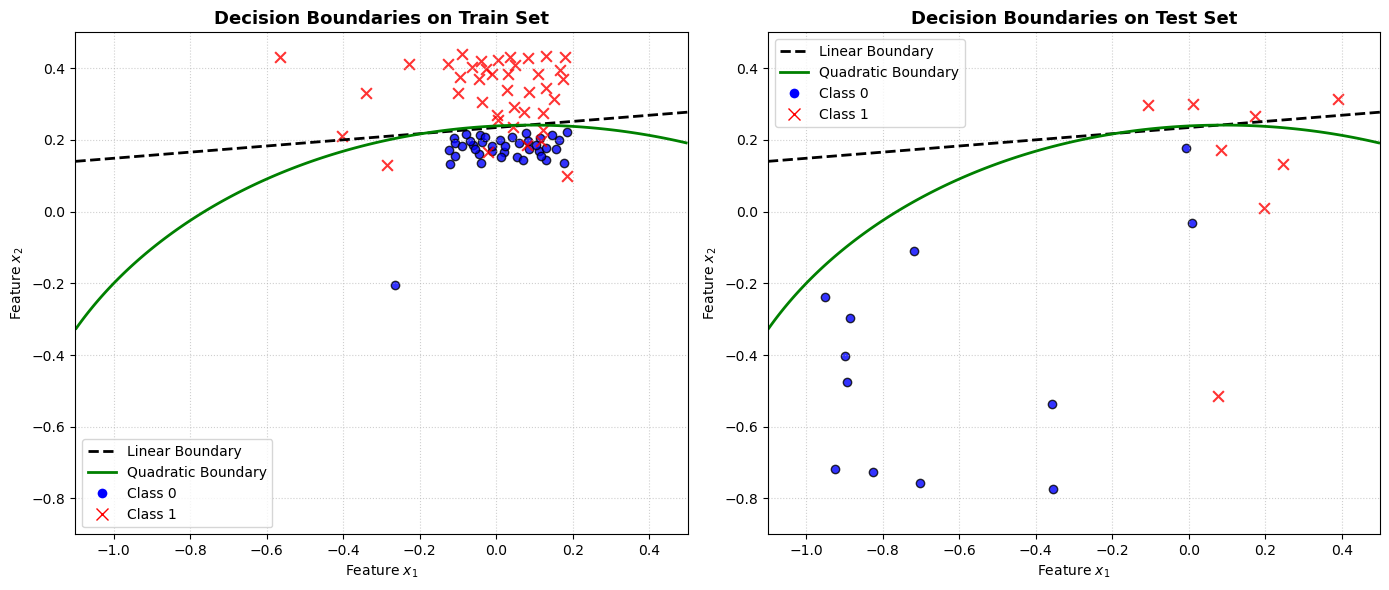

In [8]:
# Visualizing Decision Boundaries on Train and Test Sets
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

u = np.linspace(-1.1, 0.5, 300)
v = np.linspace(-0.9, 0.5, 300)
U, V = np.meshgrid(u, v)
grid_pts = np.column_stack([U.ravel(), V.ravel()])

Z_lin = sigmoid(np.column_stack([np.ones(len(grid_pts)), grid_pts]) @ theta_lin).reshape(U.shape)
Z_p2 = sigmoid(poly2.transform(grid_pts) @ theta_p2).reshape(U.shape)

for ax, split, X_data, y_data in zip(axes, ['Train Set', 'Test Set'], [X_tr, X_te], [y_tr, y_te]):
    ax.scatter(X_data[y_data == 0, 0], X_data[y_data == 0, 1], color='blue', label='Class 0', alpha=0.8, edgecolors='k')
    ax.scatter(X_data[y_data == 1, 0], X_data[y_data == 1, 1], color='red', marker='x', s=60, label='Class 1', alpha=0.8)
    ax.contour(U, V, Z_lin, levels=[0.5], colors='black', linestyles='--', linewidths=2)
    ax.contour(U, V, Z_p2, levels=[0.5], colors='green', linestyles='-', linewidths=2)
    ax.set_title(f'Decision Boundaries on {split}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Feature $x_1$')
    ax.set_ylabel('Feature $x_2$')
    ax.grid(True, linestyle=':', alpha=0.6)

custom_lines = [
    Line2D([0], [0], color='black', lw=2, linestyle='--'),
    Line2D([0], [0], color='green', lw=2, linestyle='-'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8),
    Line2D([0], [0], marker='x', color='red', lw=0, markersize=8)
]
axes[0].legend(custom_lines, ['Linear Boundary', 'Quadratic Boundary', 'Class 0', 'Class 1'], loc='lower left')
axes[1].legend(custom_lines, ['Linear Boundary', 'Quadratic Boundary', 'Class 0', 'Class 1'], loc='upper left')

plt.tight_layout()
plt.show()


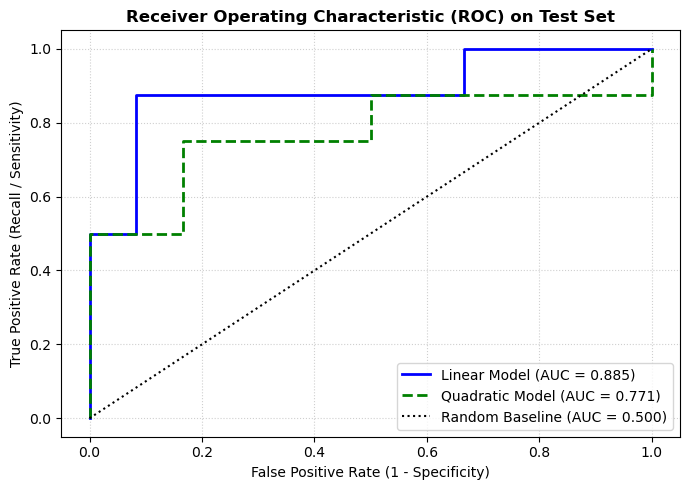

In [9]:
# ROC Curves
fpr_lin, tpr_lin, _ = roc_curve(y_te, prob_lin)
fpr_p2, tpr_p2, _ = roc_curve(y_te, prob_p2)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lin, tpr_lin, color='blue', lw=2, label=f'Linear Model (AUC = {roc_auc_score(y_te, prob_lin):.3f})')
plt.plot(fpr_p2, tpr_p2, color='green', lw=2, linestyle='--', label=f'Quadratic Model (AUC = {roc_auc_score(y_te, prob_p2):.3f})')
plt.plot([0, 1], [0, 1], 'k:', lw=1.5, label='Random Baseline (AUC = 0.500)')
plt.title('Receiver Operating Characteristic (ROC) on Test Set', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
